# Flat-guide GFMC on an $N\times N$ Kagome torus

Run this notebook from the repository root, or from `notebook/`. The solver is `code/gfmc/`. The graph and the disorder come from `code/kagome_qea/`. The projector is the same continuous-time Green's function Monte Carlo as `notebook/tfim_gfmc.ipynb`, with guiding function $\psi = 1$.

The operator is

$$
H = -\sum_b J_b \sigma_i^z \sigma_j^z - \Gamma \sum_i \sigma_i^x - h \sum_i \sigma_i^z.
$$

$s_i = \pm 1$. This run is the round-1 Gaussian nearest-neighbor ensemble: each stored bond has an independent $J_b \sim N(0,1)$, and $h = 0$. $\Gamma$ is a solver argument. It is not stored in the disorder.

`L` is the number of three-site cells on a side, so the lattice is $L\times L$. The torus has $3L^2$ sites and $6L^2$ bonds, and every site has degree 4. This run sets `L = 8`: 192 sites and 384 bonds. A dense $2^{192}$ matrix is not built. Exact diagonalization in this repository stops at 16 sites.


## What this run is

One periodic sample, `sample_id = 0`. The disorder stream is PCG64 with entropy `[1000, L, 0, 1]`. The projector uses its own seed, `0`. Open and periodic realizations are different streams. The open patch is counted below and is not projected.

The $\Gamma$ grid is the round-1 window, seven values from $0.5$ to $3.5$. Each value is one population of 2500 walkers. `n_walkers` is that population size, not the power in $(\Lambda - H)^n$. The projection length is $(40 + 160) \times 0.2 = 40$, and the reported energies use the last 160 blocks. A short timing of the $8\times 8$ torus gave about $0.47$ s per block at $\Gamma = 1$. The hop rate is $3L^2\Gamma$, so the grid is about 20–25 minutes. Larger $\Gamma$ takes longer.

This is one draw of $J$, not a disorder average and not a finite-size crossing. The error is the autocorrelation-aware standard error from `series_error`. `resolved` means the measured series has at least 64 values, its positive sequence terminated, and it has at least 8 estimated independent samples. That flag is a length check, not a coverage certificate.

A finished row is left on disk. Running the cell again loads it. The $6\times 6$ files stay in `L6/` and are not reused.

```text
data/kagome/gaussian_nn/pbc/L{L}/gfmc/h0/gamma{gamma}/sample0_seed0.npz
```

A decimal point in `gamma` is written as `p`.


In [1]:
from pathlib import Path
import sys
import time

import numpy as np

root = Path.cwd()
if not (root / "code").exists():
    root = root.parent
sys.path.insert(0, str(root / "code"))

from gfmc import GFMC
from kagome_qea import build_kagome, make_sample

L = 10
SAMPLE_ID = 0
GAMMAS = (0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5)
FIELD = 0.0
PROJECTOR_SEED = 0
SETTINGS = dict(n_walkers=2500, tau_block=0.2, n_equilibrate=40, n_measure=160)

def token(value):
    text = f"{float(value):.8f}".rstrip("0").rstrip(".")
    if text in ("", "-0"):
        text = "0"
    return text.replace("-", "m").replace(".", "p")

def run_path(gamma):
    directory = (
        root / "data" / "kagome" / "gaussian_nn" / "pbc"
        / f"L{L}" / "gfmc" / f"h{token(FIELD)}" / f"gamma{token(gamma)}"
    )
    return directory / f"sample{SAMPLE_ID}_seed{PROJECTOR_SEED}.npz"


In [2]:
def expected_counts(periodic):
    n_sites = 3 * L * L
    if periodic:
        return n_sites, 6 * L * L, 2 * L * L
    return n_sites, 6 * L * L - 4 * L + 1, L * L + (L - 1) * (L - 1)

def summarize(periodic):
    points, bonds, triangles, adjacency = build_kagome(L, periodic=periodic)
    degrees = np.asarray(adjacency.sum(axis=1), dtype=int)
    counts = {int(degree): int(np.count_nonzero(degrees == degree)) for degree in np.unique(degrees)}
    n_sites, n_bonds, n_triangles = expected_counts(periodic)
    print(
        f"{'pbc' if periodic else 'obc':<4} sites {points.shape[0]:3d}  "
        f"bonds {bonds.shape[0]:3d}  triangles {len(triangles):3d}  degrees {counts}"
    )
    if points.shape[0] != n_sites or bonds.shape[0] != n_bonds or len(triangles) != n_triangles:
        raise RuntimeError(f"L={L} counts do not match the closed form")
    if periodic and not np.all(degrees == 4):
        raise RuntimeError(f"periodic L={L} is not degree 4 at every site")
    return points, bonds, triangles, degrees

if L < 2:
    raise RuntimeError("the Kagome torus needs L >= 2")
summarize(False)
points, bonds, triangles, degrees = summarize(True)

sample = make_sample(L, True, SAMPLE_ID)
print(
    f"sample {sample.sample_id}  entropy {sample.seed_entropy.tolist()}  "
    f"J mean {sample.J.mean():.4f}  J std {sample.J.std():.4f}"
)
operator = sample.hamiltonian(FIELD)


obc  sites 300  bonds 561  triangles 181  degrees {2: 21, 3: 36, 4: 243}
pbc  sites 300  bonds 600  triangles 200  degrees {4: 300}
sample 0  entropy [1000, 10, 0, 1]  J mean 0.0203  J std 1.0208


## The energies in the table

The run estimates one ground-state energy, $E_0$, of this sample at the chosen $\Gamma$. The mixed column and the growth column are two readings of that energy from the same walkers. $E/N$ is the mixed energy divided by the number of sites. $E_T$ is the shift that keeps the walker weights finite.

### Local energy

The guiding function is $\psi = 1$, so every configuration has flip rate $\lambda = N\Gamma$. The diagonal energy and the local energy are

$$
E_{\mathrm{diag}}(s) = -\sum_b J_b s_i s_j - h \sum_i s_i,
$$

$$
E_L(s) = E_{\mathrm{diag}}(s) - N\Gamma.
$$

A walker that sits on $s$ for a time $\Delta\tau$ has its weight updated by

$$
w \leftarrow w \exp\bigl[-\Delta\tau\bigl(E_L(s) - E_T\bigr)\bigr].
$$

### Trial energy $E_T$

The walkers begin as random $\pm 1$ states, and the first shift is their average local energy,

$$
E_T = \frac{1}{n_{\mathrm{walkers}}}\sum_s E_L(s).
$$

For $\psi = 1$ the random diagonal energy is near zero, so this start is near $-N\Gamma$. After every block, including the 40 warmup blocks,

$$
E_T \leftarrow \frac{E_T + E_{\mathrm{growth}}}{2}.
$$

The growth value on the right is computed in that block with the old $E_T$.

### Mixed energy

$$
E_{\mathrm{mixed}} = \frac{\langle\psi|H|\psi(\tau)\rangle}{\langle\psi|\psi(\tau)\rangle}.
$$

With $\psi = 1$, one block is the weight-and-time average of the local energy,

$$
E_{\mathrm{mixed}} = \frac{\sum_{\mathrm{walkers}}\int_0^{\tau_{\mathrm{block}}} w(t)\, E_L(t)\, dt}{\sum_{\mathrm{walkers}}\int_0^{\tau_{\mathrm{block}}} w(t)\, dt}.
$$

When the population has projected onto the ground state, $H|\psi_0\rangle = E_0|\psi_0\rangle$, and this ratio equals $E_0$.

### Growth energy

Each walker starts a block at weight 1, so the total weight starts at $n_{\mathrm{walkers}}$. If $W$ is the total weight at the end of the block,

$$
E_{\mathrm{growth}} = E_T - \frac{1}{\tau_{\mathrm{block}}}\log\frac{W}{n_{\mathrm{walkers}}}.
$$

The ground-state piece of the population grows as $e^{-\tau E_0}$. The weight update already removes $E_T$, so the change in $\log W$ measures $E_T - E_0$.

### What is printed

Each of the 160 measurement blocks stores one $E_{\mathrm{mixed}}$ and one $E_{\mathrm{growth}}$. The table prints the mean of each series. The `err` column is the standard error of that mean. Successive blocks are correlated, and `series_error` widens the error for that correlation. The column $E/N$ is the mixed mean divided by the number of sites. In the plot, both energies and both errors are divided by the number of sites.

After a long projection the two means both equal $E_0$. In this finite run each still carries the statistical error in its column, a bias from the finite projection length, and a population-control bias of order $1/n_{\mathrm{walkers}}$.


In [3]:
def load_row(path):
    with np.load(path, allow_pickle=False) as data:
        row = {}
        for key in data.files:
            value = data[key]
            row[key] = value.item() if value.shape == () else np.array(value)
        return row

rows = []
for gamma in GAMMAS:
    path = run_path(gamma)
    if path.exists():
        row = load_row(path)
        print(f"loaded  Γ={gamma:.1f}  {path.relative_to(root)}", flush=True)
    else:
        started = time.perf_counter()
        result = GFMC(operator, gamma, h=FIELD).run(seed=PROJECTOR_SEED, **SETTINGS)
        seconds = time.perf_counter() - started
        path.parent.mkdir(parents=True, exist_ok=True)
        np.savez_compressed(
            path,
            L=np.int64(sample.L),
            periodic=np.bool_(sample.periodic),
            sample_id=np.int64(sample.sample_id),
            ensemble=np.array(sample.ensemble),
            seed_entropy=np.asarray(sample.seed_entropy, dtype=np.int64),
            gamma=np.float64(gamma),
            h=np.float64(FIELD),
            seed=np.int64(PROJECTOR_SEED),
            n_walkers=np.int64(SETTINGS["n_walkers"]),
            tau_block=np.float64(SETTINGS["tau_block"]),
            n_equilibrate=np.int64(SETTINGS["n_equilibrate"]),
            n_measure=np.int64(SETTINGS["n_measure"]),
            n_sites=np.int64(sample.n_sites),
            seconds=np.float64(seconds),
            energy=np.float64(result["energy"]),
            energy_error=np.float64(result["energy_error"]),
            energy_growth=np.float64(result["energy_growth"]),
            energy_growth_error=np.float64(result["energy_growth_error"]),
            energy_resolved=np.bool_(result["energy_resolved"]),
            energy_growth_resolved=np.bool_(result["energy_growth_resolved"]),
            energy_series=np.asarray(result["energy_series"], dtype=np.float64),
            energy_growth_series=np.asarray(result["energy_growth_series"], dtype=np.float64),
            J=np.asarray(sample.J, dtype=np.float64),
        )
        row = load_row(path)
        print(
            f"ran     Γ={gamma:.1f}  {seconds:6.1f}s  "
            f"mixed {result['energy']:.4f} ± {result['energy_error']:.4f}  "
            f"resolved {result['energy_resolved']}",
            flush=True,
        )
    rows.append(row)

n_sites = int(rows[0]["n_sites"])
header = (
    f"{'Γ':>5} {'mixed':>10} {'err':>8} {'growth':>10} {'err':>8} "
    f"{'E/N':>8} {'flag':>5} {'growth flag':>11}"
)
print(header)
for row in rows:
    print(
        f"{row['gamma']:5.1f} {row['energy']:10.4f} {row['energy_error']:8.4f} "
        f"{row['energy_growth']:10.4f} {row['energy_growth_error']:8.4f} "
        f"{row['energy'] / n_sites:8.4f} {str(bool(row['energy_resolved'])):>5} "
        f"{str(bool(row['energy_growth_resolved'])):>11}"
    )


ran     Γ=0.5    75.5s  mixed -289.9487 ± 1.6962  resolved True
ran     Γ=1.0   150.7s  mixed -394.1839 ± 1.1937  resolved True
ran     Γ=1.5   230.0s  mixed -522.0168 ± 1.0240  resolved True
ran     Γ=2.0   307.0s  mixed -661.1608 ± 0.8004  resolved True
ran     Γ=2.5   373.8s  mixed -799.9480 ± 1.2135  resolved True
ran     Γ=3.0   444.8s  mixed -944.3355 ± 0.7691  resolved True
ran     Γ=3.5   518.8s  mixed -1089.1979 ± 0.5193  resolved True
    Γ      mixed      err     growth      err      E/N  flag growth flag
  0.5  -289.9487   1.6962  -289.8640   1.6833  -0.9665  True        True
  1.0  -394.1839   1.1937  -393.9157   1.2243  -1.3139  True        True
  1.5  -522.0168   1.0240  -521.9700   1.0243  -1.7401  True        True
  2.0  -661.1608   0.8004  -661.1655   0.7564  -2.2039  True        True
  2.5  -799.9480   1.2135  -799.9715   1.1951  -2.6665  True        True
  3.0  -944.3355   0.7691  -944.1053   0.6750  -3.1478  True        True
  3.5 -1089.1979   0.5193 -1089.1011   0

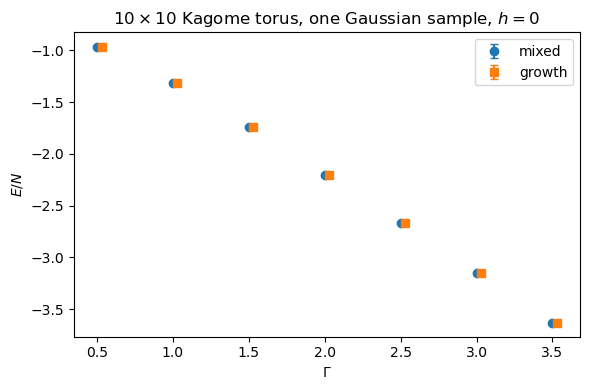

In [4]:
import matplotlib.pyplot as plt

gammas = np.array([row["gamma"] for row in rows], dtype=float)
mixed = np.array([row["energy"] for row in rows], dtype=float) / n_sites
mixed_error = np.array([row["energy_error"] for row in rows], dtype=float) / n_sites
growth = np.array([row["energy_growth"] for row in rows], dtype=float) / n_sites
growth_error = np.array([row["energy_growth_error"] for row in rows], dtype=float) / n_sites

figure, axis = plt.subplots(figsize=(6.0, 4.0))
axis.errorbar(gammas, mixed, yerr=mixed_error, fmt="o", capsize=3, label="mixed")
axis.errorbar(gammas + 0.03, growth, yerr=growth_error, fmt="s", capsize=3, label="growth")
axis.set_xlabel(r"$\Gamma$")
axis.set_ylabel("$E / N$")
axis.set_title(rf"${L}\times {L}$ Kagome torus, one Gaussian sample, $h = 0$")
axis.legend()
figure.tight_layout()
plt.show()
